# Instructions
## Goal
The goal of this notebook is to investigate how the values of the site-specific covariates:
1. mean lnSARatio 
2. mean lnRSD595
3. sigma lnSARatio
4. sigma lnRSD595

vary at each of the sites with RTP/IML. I want to identify if there are any obvious trends/patterns etc across the sites that I could leverage to help guide the developement of a simplified model for predicting these values at a site (e.g. based on the disaggregation results, or geographic location.) so that they can be used inconjunction with the models developed in notebook 073 to predict the difference between MSA-SS and IDA-FX at a particular site.

All images and datasets created by of this notebook should be save in 

## Implementation Stages:
This is a large task and should be broken down into several stages:

### Stage 1:
For a single site calculate the SARatio for structures with periods upto 2s conditional on AvgSA[0,3] using the target GCIM distributions for all available IMLs (AvgSA)/RTPs at that site.

Plot a SARatio surface with SARatio on the Z axis (vertical) and Period and conditioning level (AvgSA[0,3]) on the horizontal axes. Repeat the plot for RTP as 
well by using the site specific hazard curve to convert the IML to RTP using linear interpolation in logspace

Plot 2D Plots of SARatio vs. AvgSA/RTP showing lines for T1 = 0.25, 0.5, 0.75, and 1.0s

Do a similar set of plot for sigma lnSARatio (surface and 2D Plots)

Do 2D plots of RSD595 and sigma RSD595 vs AvgSA/RTP

The plotted images should be saved in a new folder in /processed_data

### Stage 2:
The records selected for each site do not always match perfectly the median and standard deviation of the GCIM.
I want to know what sort of size the error is.

For each record set that we have selected in "C:\Users\clemettn\Documents\phd\results\04_record_selection\AvgSA_03":
calculate the SARatio distribution for T values up to 2s as well as sigma ln SARatio, RSD595 and sigma RSD595.
We don't need to calculate the spectra ourselves. You should be able to read it from gm selection .pickle files.

for each IML that we have records for compare the GCIM values with the values from the actual record set. Do this first just for the periods of the structures specific to each site.

### Stage 3:
extend the the code to do the calculations for all sites. Produce all the same plots.
The plots for each site should be saved in their own folder.

Create plots the show how SARatio vs. AvgSA/RTP for T1 = 0.25, 0.5, 0.75, and 1.0s varies across the sites. There should be one plot for each period. Each plot should have 60 lines (one for each site) and clearly show the median and the +/- 1 and 2 standard deviations.

Similarly do this for the other 3 covariates








# 074 — Trends in the site covariates (Stage 1: one site; Stage 3: all 60 sites)

Nb 073 explains the MSA-SS vs IDA-FX difference with four ground-motion covariates of the site-specific record
sets. Each one is a property of the GCIM target distribution, conditioned on AvgSA$_{0-3}$ = level:

| covariate | symbol | depends on |
|---|---|---|
| mean ln SaRatio | $E[\ln \mathrm{SaRatio}(T_1)]$ | site, **structure period**, level |
| sigma ln SaRatio | $SD[\ln \mathrm{SaRatio}(T_1)]$ | site, **structure period**, level |
| mean ln RSD595 | $E[\ln D_{s5-95}]$ | site, level |
| sigma ln RSD595 | $SD[\ln D_{s5-95}]$ | site, level |

Nb 072 evaluates them only at four return periods and at the site's two structure periods. **This notebook maps the
whole surface**, over periods 0.15–2 s and every intensity level we hold a disaggregation for:

* first for one site (Stage 1, sections 1–7);
* then for all 60 sites, with cross-site plots (Stage 3, sections 8–10).

The aim is to see what shape a simplified predictor would have to reproduce. Stage 2 (selected record sets vs GCIM
target) comes later.

**SaRatio** (Eads et al. 2016; Zhong et al. 2022, *Earthquake Spectra* 38(3), Eq. 2, ~p. 1897, page approximate):

$$\ln\mathrm{SaRatio}(T_1) = \ln \mathrm{SA}(T_1) - \frac1n\sum_{i=1}^{n}\ln \mathrm{SA}(T_i),
\qquad T_i \in [0.2T_1 : 0.01\,\mathrm{s} : 3T_1].$$

Think of it as "how tall is the spectrum at $T_1$ compared with its average height over the band the structure moves
through as it softens". **Low SaRatio means a flatter, broader spectrum, which is the more damaging shape.**

**How it is computed.** Everything comes from `phd_project/scripts/gcim_saratio.py`, which nb 072 also uses. The
GCIM (Bradley 2010) is a **mixture** over the disaggregated rupture scenarios:

* within one scenario, ln SaRatio is a linear combination of jointly normal log-ordinates, so its mean and variance
  are closed form;
* across scenarios, the law of total variance applies:
  $\mathrm{Var} = \underbrace{\sum_k w_k v_k}_{\text{within}} +
  \underbrace{\sum_k w_k m_k^2 - (\sum_k w_k m_k)^2}_{\text{between}}$
  (Ang & Tang 2007, *Probability Concepts in Engineering*, 2nd ed., Ch. 3, ~p. 130, page approximate).

The *between* term is only large where the scenarios disagree about the spectral shape, for example crustal vs
subduction events. That is why Stage 1 uses a **mixed-TRT site**.

**The intensity levels** are all the levels the site has a disaggregation for:

1. the 27-IML disaggregation grid of nb 020/021 (fixed IMLs, the same at every site), minus any IML beyond the 4σ
   truncation at that site;
2. the four return-period levels (475, 2500, 5000, 10 000 yr) disaggregated for nb 072.

Each level is converted to a return period by reading the site's mean AvgSA$_{0-3}$ hazard curve linearly in
log-log space.

Outputs go to `data_processed/12_site_covariate_trends/site_NNN/` (per site) and `.../cross_site/` (Stage 3).

In [1]:
%load_ext autoreload
%autoreload 2

## 0. Setup & parameters

In [2]:
import gc
import json
import pickle
import time
from pathlib import Path

import numpy as np
import psutil
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from phd_project.config import config
from phd_project.scripts import gcim_saratio as gsr
from phd_project.scripts.cache_utils import fingerprint, load_or_compute, manifest_matches
from phd_project.scripts.disagg_shards import load_shards, read_index, stripe_content_hash

cfg = config.load_config()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

C:\Users\clemettn\Documents\phd\phd_project\scripts\WP1_ground_motion_set\gm_selection.py:15: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [3]:
# -----------------------------------------------------------------------------
# PARAMETERS
# -----------------------------------------------------------------------------
IM_TAG = "AvgSA_03"     # conditioning IM of the whole study (AvgSA over 0-3 s)
IMT = "AvgSA"           # its key in the hazard-curve / disaggregation dicts
N_SITES = 60
RTPS = (475, 2500, 5000, 10000)   # the return-period levels disaggregated for nb 072 [yr]

# SITE = None -> pick the most evenly mixed-TRT site automatically (section 2).
# Set an int to override.
SITE = None
# Return period whose disaggregation is used to rank the sites by TRT mixing.
MIX_RANK_RTP = 2500

# Period grid for the SaRatio surface.
# * 0.05 s steps make every band end, 0.2*T and 3*T, a multiple of 0.01 s, so
#   all the grid bands share the same 0.01 s period steps (section 4 puts every
#   period a site needs on one axis and runs the GMMs once per level).
# * It starts at 0.15 s because the correlation model starts at 0.025 s and the
#   band starts at 0.2*T1, so 0.2 * 0.15 = 0.03 s is the smallest band period.
# * It ends at 2 s, so the band reaches 3 * 2 = 6 s, within the correlation
#   model (8 s) and the GMMs.
T_GRID = np.round(np.arange(0.15, 2.0 + 1e-9, 0.05), 2)

# The four periods of the 2-D line plots (the brief).
LINE_T1S = [0.25, 0.5, 0.75, 1.0]
assert all(np.isclose(T_GRID, t).any() for t in LINE_T1S)

# Set True to ignore the caches and recompute everything.
FORCE_RECOMPUTE = False

# -----------------------------------------------------------------------------
# PATHS
# -----------------------------------------------------------------------------
SHARD_DIR = Path(cfg["proc_data"]["AvgSA_03_disagg_data_shards"])
EXCLUDED_FP = SHARD_DIR.parent / f"{IM_TAG}_excluded_imls_wp1sites_eps4.json"
REG_PTH = Path(cfg["proc_data"]["bootstrapping"]).parent / "regression_coefficients"
DISAGG_RTPS_FP = REG_PTH / f"{IM_TAG}_disagg_rtps_eps4.pickle"   # nb 072 s.8.3
GCIM_RTPS_FP = REG_PTH / f"gcim_{IM_TAG}_rtps.pickle"            # nb 072 s.8.5
GCIM_STRIPES_FP = Path(cfg["proc_data"]["gcim_dists"]) / f"gcim_dist_{IM_TAG}.pickle"  # nb 031
STRUCT_DIR = Path(cfg["proc_data"]["unique_structural_designs_csv"]).parent
DESIGNS_FP = STRUCT_DIR / "unique_structural_designs.csv"             # site -> design group
GROUP_PROPS_FP = STRUCT_DIR / "design_group_structure_properties.csv"  # design group -> T1
OUT_ROOT = Path(cfg["proc_data"]["root"]) / "12_site_covariate_trends"

## 1. Structure periods

$T_1$ is the modal first-mode period of each design group's OpenSees model
(`design_group_structure_properties.csv`, column `T1_modal_s`). Groups are mapped to sites through
`unique_structural_designs.csv`. The group label is `group_{storeys}s_{group_id:02d}`, the same `design_group_id`
nb 072 uses. Every site carries two structures, a 3-storey and a 5-storey, so the join must give 120 rows.

The structure periods are marked on the surfaces as reference lines. Their SaRatio moments are also computed
exactly (section 4), not interpolated off the grid.

In [4]:
designs = pd.read_csv(DESIGNS_FP)
group_props = pd.read_csv(GROUP_PROPS_FP)

# Build the design-group label that design_group_structure_properties.csv is keyed on.
designs["design_group_id"] = [f"group_{n}s_{g:02d}" for n, g in zip(designs["storeys"], designs["group_id"])]
structures = designs.merge(group_props[["design_group_id", "T1_modal_s"]],
                           on="design_group_id", how="left", validate="m:1")

# 60 sites x {3s, 5s}, every one with a period (CLAUDE.md s.1).
assert len(structures) == 2 * N_SITES, len(structures)
assert structures["T1_modal_s"].notna().all(), "a design group has no modal period"
assert (structures.groupby("site")["storeys"].apply(sorted).apply(tuple) == (3, 5)).all()
# Every structure period must sit inside the SaRatio machinery's valid range.
assert structures["T1_modal_s"].between(T_GRID.min(), T_GRID.max()).all()

structures["T1_modal_s"].describe().round(3).to_frame().T

,count,mean,std,min,25%,50%,75%,max
T1_modal_s,120.0,0.627,0.185,0.311,0.485,0.613,0.758,0.911


## 2. Shared inputs and the Stage 1 site

Everything that does not depend on the site is loaded once here and shared by Stage 1 and Stage 3:

* the AvgSA hazard curves;
* the disaggregation index;
* the excluded-IML list;
* nb 072's return-period disaggregations and GCIMs;
* nb 031's GCIMs of the analysed stripes.

**Choosing the Stage 1 site.** The ranking uses the `MIX_RANK_RTP`-yr disaggregation. It sums the scenario
probabilities by Tectonic Region Type and ranks the sites by the weight of their **second** TRT. A site at 50 / 50
has two genuinely competing source types. That is where the between-scenario variance, and any disagreement in
spectral shape, should be largest.

In [5]:
# ---- shared, site-independent inputs ---------------------------------------------
with open(DISAGG_RTPS_FP, "rb") as f:
    disagg_rtps = pickle.load(f)   # {"disagg": {(site, R): df}, "iml": {(site, R): g}, "summary": df}
# ---- the two existing GCIM caches, reduced to the few numbers used here ------------
# Both files hold full GCIM distributions (stats + pdf/cdf curves for 22 IMs) for
# hundreds of (site, level) pairs. This notebook needs only the RSD595 moments,
# the analysed-stripe IMLs and nb 072's SaRatio table, so everything else is
# dropped straight after loading. Holding the full dicts through a 60-site run
# is what ran the machine out of memory.
def _rsd595(stats):
    # (mean, sigma) of ln RSD595 from one GCIM `stats` table
    return float(stats.loc["RSD595", "mean"]), float(stats.loc["RSD595", "sigma"])


_g = pd.read_pickle(GCIM_RTPS_FP)          # nb 072: {"rsd", "saratio", "gcim": {(site, R): {...}}}
NB072_SARATIO = _g["saratio"]              # structure-period ln SaRatio moments at the 4 RTPs
RTP_RSD = {key: _rsd595(v["stats"]) for key, v in _g["gcim"].items()}      # {(site, R): (mean, sigma)}
with open(GCIM_STRIPES_FP, "rb") as f:
    _g = pickle.load(f)                    # nb 031: {(site, iml): {"stats", "pdfs", "cdfs"}}
STRIPE_RSD = {key: _rsd595(v["stats"]) for key, v in _g.items()}         # {(site, iml): (mean, sigma)}
del _g
gc.collect()

with open(EXCLUDED_FP) as f:
    EXCLUDED = {int(s): v for s, v in json.load(f).items()}   # IMLs beyond the 4 sigma truncation
SHARD_INDEX = read_index(SHARD_DIR)        # {site: {"AvgSA": [grid imls]}}, no shard opened
HAZARD = pd.read_pickle(cfg["proc_data"]["AvgSA_03_hazard_curves_4sig"])


def site_dir(site):
    # One output folder per site: data_processed/12_site_covariate_trends/site_NNN/
    d = OUT_ROOT / f"site_{site:03d}"
    d.mkdir(parents=True, exist_ok=True)
    return d


def structure_T1s(site):
    # {storeys: modal T1} of the two structures at a site (section 1 join).
    s = structures.query("site == @site").sort_values("storeys")
    return dict(zip(s["storeys"].astype(int), s["T1_modal_s"].astype(float)))


# ---- rank the sites by TRT mixing and choose the Stage 1 site ----------------------
mix_rows = []
for s in range(N_SITES):
    w = disagg_rtps["disagg"][(s, MIX_RANK_RTP)].groupby("TRT")["P(m|X=x)"].sum()
    w = (w / w.sum()).sort_values(ascending=False)
    mix_rows.append({"site": s,
                     "trt_1": w.index[0], "w_1": w.iloc[0],
                     "trt_2": w.index[1] if len(w) > 1 else None,
                     "w_2": w.iloc[1] if len(w) > 1 else 0.0,
                     "n_trt": int((w > 0.01).sum())})
trt_mix = pd.DataFrame(mix_rows).sort_values("w_2", ascending=False).reset_index(drop=True)

if SITE is None:
    SITE = int(trt_mix.loc[0, "site"])
print(f"SITE = {SITE}")
print("structure periods:", {f"{n}s": round(t, 3) for n, t in structure_T1s(SITE).items()})
trt_mix.head(8).round(3)

SITE = 34
structure periods: {'3s': 0.333, '5s': 0.572}


,site,trt_1,w_1,trt_2,w_2,n_trt
0,34,Shallow Default,0.521,Subduction Interface,0.461,3
1,17,Subduction Interface,0.427,Shallow Default,0.396,3
2,42,Subduction Interface,0.576,Shallow Default,0.394,3
3,12,Shallow Default,0.539,Subduction Inslab,0.378,3
4,18,Subduction Inslab,0.373,Shallow Default,0.358,3
5,24,Subduction Inslab,0.411,Shallow Default,0.314,3
6,27,Non-Subduction Deep,0.701,Shallow Default,0.299,2
7,41,Shallow Default,0.745,Subduction Interface,0.241,3


## 3. The intensity levels and their return periods

Each level has an IML (AvgSA$_{0-3}$, g), a return period, and the disaggregation it is conditioned on.

* **Grid levels** (`source = "grid"`): these are the disaggregation shards of nb 021. IMLs listed for the site in
  `*_excluded_imls_*.json` are beyond the 4σ truncation (zero hazard) and are dropped.
* **RTP levels** (`source = "rtp"`): these are nb 072's disaggregations at each site's own 475 / 2500 / 5000 /
  10 000-yr level. OpenQuake found the level itself (`hmap3`). Its return period is the nominal R.

The return period of a grid level is read from the mean AvgSA hazard curve, **linearly in log-log space**. That is the
only sensible reading of a curve spanning many orders of magnitude between 25 tabulated points. Outside the positive
part of the curve the result is NaN, never an extrapolation. The helpers are those of nb 078, s.4.

As a check, the log-log reading of the curve at R must reproduce the IML OpenQuake disaggregated at, to within 3 %.
The comparison is made in IML, not in return period. OpenQuake interpolates its own hazard map, and on a flat stretch
of curve a small IML difference becomes a larger return-period one. At sites 22 and 27 the IMLs agree to 1.7 %, but
the return periods differ by up to 7 %. The RTP levels keep their nominal R, which is what was disaggregated.

`build_levels(site)` only reads the disaggregation *index*, so it is cheap. The disaggregations themselves (~70 MB per
site) are loaded by `level_disaggs` only when something has to be computed. The IMLs analysed as MSA stripes at the
site (nb 031's `gcim_dist` keys) are also returned and marked on the plots.

In [6]:
def _positive(hc):
    # Rows of an (n, 2) [IML, MAFE] curve with MAFE > 0, i.e. without the zero
    # tail beyond the truncation ceiling (the log of zero is undefined).
    hc = np.asarray(hc, dtype=float)
    return hc[hc[:, 1] > 0.0]


def rtp_at_iml(hc, iml):
    # Return period [yr] of intensity `iml` [g]: forward reading of the curve,
    # linear in log-log. NaN when iml is outside the positive part of the curve.
    pos = _positive(hc)
    if len(pos) < 2 or not (pos[0, 0] <= iml <= pos[-1, 0]):
        return np.nan
    return float(1.0 / np.exp(np.interp(np.log(iml), np.log(pos[:, 0]), np.log(pos[:, 1]))))


def iml_at_rtp(hc, rtp):
    # IML [g] at return period `rtp` [yr]: invert the curve at MAFE = 1/rtp,
    # linear in log-log (MAFE descends along the curve, hence the reversal).
    # NaN when 1/rtp is outside the positive part of the curve.
    pos = _positive(hc)
    target = 1.0 / rtp
    if len(pos) < 2 or not (pos[:, 1].min() <= target <= pos[:, 1].max()):
        return np.nan
    return float(np.exp(np.interp(np.log(target), np.log(pos[::-1, 1]), np.log(pos[::-1, 0]))))


def build_levels(site):
    """The levels of one site: DataFrame (level, source, iml, rtp, R) plus the analysed stripes."""
    hc = HAZARD[site][IMT]["mean"]
    excluded = EXCLUDED.get(site, [])

    # ---- grid levels: the IMLs in this site's disaggregation shard --------------
    rows = []
    for iml in sorted(SHARD_INDEX[site][IMT]):
        if any(np.isclose(iml, x) for x in excluded):
            continue
        rows.append({"level": f"grid_{iml:.4f}", "source": "grid", "iml": float(iml),
                     "rtp": rtp_at_iml(hc, iml), "R": np.nan})

    # ---- RTP levels: nb 072's disaggregations at fixed return periods ------------
    for R in RTPS:
        iml = float(disagg_rtps["iml"][(site, R)])
        rows.append({"level": f"rtp{R}", "source": "rtp", "iml": iml, "rtp": float(R), "R": R})
        # Check: the log-log reading of the curve reproduces the level OpenQuake
        # found, compared in INTENSITY. OpenQuake interpolates its own hazard
        # map between the tabulated curve points, and on a flat stretch of curve
        # a sub-2 % difference in IML becomes a larger one in return period
        # (up to 7 % at sites 22 and 27). The IML is what the GCIM is
        # conditioned on, so that is where agreement matters; max found 1.7 %.
        iml_ll = iml_at_rtp(hc, R)
        assert abs(np.log(iml / iml_ll)) < 0.03, (
            f"site {site} rtp{R}: OQ level {iml:.4f} g vs log-log curve reading {iml_ll:.4f} g")

    levels = pd.DataFrame(rows).sort_values("iml").reset_index(drop=True)
    # Return period must increase with intensity; check it wherever it is defined.
    assert levels.dropna(subset=["rtp"])["rtp"].is_monotonic_increasing, f"site {site}: rtp not monotonic"

    analysed = sorted(k[1] for k in STRIPE_RSD if k[0] == site)
    return {"levels": levels, "n_excluded": len(excluded),
            "analysed_imls": analysed,
            "analysed_rtps": [rtp_at_iml(hc, x) for x in analysed]}


def level_disaggs(site, levels):
    """{level: disaggregation DataFrame}. Opens the site's shard, so call only when computing."""
    shard = load_shards(SHARD_DIR, {site})[site][IMT]          # {native iml: df}
    out = {}
    for r in levels.itertuples():
        if r.source == "grid":
            native = next(k for k in shard if np.isclose(k, r.iml))
            out[r.level] = shard[native]
        else:
            out[r.level] = disagg_rtps["disagg"][(site, int(r.R))]
    return out


lv1 = build_levels(SITE)
print(f"{len(lv1['levels'])} levels: {(lv1['levels'].source == 'grid').sum()} grid "
      f"({lv1['n_excluded']} excluded beyond truncation) + {(lv1['levels'].source == 'rtp').sum()} rtp")
print(f"{lv1['levels']['rtp'].isna().sum()} grid level(s) beyond the positive hazard curve -> "
      f"shown on AvgSA plots only, not on RTP plots")
print(f"analysed MSA stripes: {lv1['analysed_imls']}")
lv1["levels"].round(4)

32 levels: 28 grid (0 excluded beyond truncation) + 4 rtp
0 grid level(s) beyond the positive hazard curve -> shown on AvgSA plots only, not on RTP plots
analysed MSA stripes: [0.4, 0.45, 0.5, 0.55, 0.65, 0.8, 0.8904, 0.95, 1.15, 1.3368]


,level,source,iml,rtp,R
0,rtp475,rtp,0.1507,4.750000e+02,475.0
1,grid_0.1645,grid,0.1645,5.795591e+02,NaN
2,grid_0.2109,grid,0.2109,1.116867e+03,NaN
3,grid_0.2423,grid,0.2423,1.624645e+03,NaN
4,grid_0.2700,grid,0.2700,2.248872e+03,NaN
5,rtp2500,rtp,0.2797,2.500000e+03,2500.0
6,grid_0.2850,grid,0.2850,2.645425e+03,NaN
7,grid_0.3100,grid,0.3100,3.405509e+03,NaN
8,grid_0.3300,grid,0.3300,4.109037e+03,NaN
9,grid_0.3434,grid,0.3434,4.644064e+03,NaN


## 4. The covariates of one site: SaRatio over the period grid, and RSD595

**The efficient route.** `gsr.expected_ln_saratio(site, T1, ...)` rebuilds the conditional spectrum of every rupture
for its own T1. Calling it for 38 grid periods plus 2 structure periods, at every level, repeats the expensive part
(the ground-motion model evaluation) 40 times per level. `ln_saratio_many` below does it **once per level** instead:

1. `site_period_axis` collects every period any of the site's T1s needs into one axis. That is each T1 (to 3 dp) and
   its whole band `gsr.saratio_periods(T1)`, for the 38 grid periods **and** the site's two structure periods. The
   grid bands all lie on the 0.01 s steps from 0.03 to 6 s. The structure bands (e.g. 0.067, 0.077, ... for
   T1 = 0.333 s) are added alongside.
2. `gsr.conditional_spectra` is called once on that axis, giving every rupture's conditional log-spectrum.
3. For each T1, its own positions are picked out of the axis and reduced with the library's `scenario_ln_saratio`
   and `combine_scenarios`, unchanged.

The periods, the bilinear correlation values and the arithmetic are exactly those of `expected_ln_saratio`, so the
numbers are identical. The checks in 4.1 (Stage 1) and 10 (Stage 3) confirm it.

An analogy: `expected_ln_saratio` photographs the whole spectrum anew for every period window. This takes one wide
photograph per level and crops it 40 times.

**RSD595** comes from row `RSD595` of the standard GCIM `stats` table
(`gm_selection.calculate_gcim_distributions_for_sites`, exactly as in nb 031 / 072). These are the mixture mean and SD
of $\ln D_{s5-95}$ from the Bahrampouri et al. (2021) GMMs. There is one value per level, since duration does not
depend on the structure. Entries already computed elsewhere are reused: analysed stripes from nb 031, return-period
levels from nb 072. The rest are computed.

**Caching.** Everything for a site goes into one pickle, `site_NNN/site_covariates.pickle` (`load_or_compute`). It is
fingerprinted on every input:
* the grid disaggregations (content hashes) and the return-period disaggregation file;
* the levels, the T grid and the structure periods;
* the site model, the GMM logic tree, the SaRatio constants;
* the `gcim_saratio.py` source, and the nb 031 / 072 GCIM files.

A change to any of them triggers a recompute of that site only.

In [7]:
from phd_project.scripts.WP1_ground_motion_set.gm_selection import calculate_gcim_distributions_for_sites
from phd_project.scripts.WP1_ground_motion_set.setup_AvgSA03_gm_selection import SELECTION_CONFIG

_GCIM_CTX = None


def gcim_ctx():
    # nb 031's selection context (GMM map, correlation models, site model, ...),
    # built once and only when something actually has to be computed. With
    # sites=() it loads no disaggregation shard; ~5-10 s.
    global _GCIM_CTX
    if _GCIM_CTX is None:
        from phd_project.scripts.WP1_ground_motion_set.setup_AvgSA03_gm_selection import (
            setup_AvgSA03_gcim_gm_selection)
        _, stats, site_model, ctx, _ = setup_AvgSA03_gcim_gm_selection(sites=())
        _GCIM_CTX = (stats, site_model, ctx)
    return _GCIM_CTX


def site_period_axis(T1s):
    """One period axis covering every T1 and every SaRatio band a site needs.

    Returns (axis, specs), where specs[j] = (T1, i_t1, i_band) holds the POSITIONS
    of T1s[j] and of its band on the axis. Periods are rounded to 3 dp exactly as
    gsr.expected_ln_saratio rounds them, so every lookup matches the library's.
    """
    per_T1 = [(float(T1), float(np.round(T1, 3)), gsr.saratio_periods(T1)) for T1 in T1s]
    axis = np.unique(np.concatenate([np.concatenate([[t1r], band]) for _, t1r, band in per_T1]))
    position_of = {float(T): i for i, T in enumerate(axis)}
    # A period missing from the axis raises KeyError here: loud, never silent.
    specs = [(T1, position_of[t1r], np.array([position_of[float(T)] for T in band]))
             for T1, t1r, band in per_T1]
    return axis, specs


def ln_saratio_many(site, axis, specs, disagg_df, iml, site_model, selection_ctx):
    """E and SD of ln SaRatio(T1) for every T1 in `specs`, at ONE conditioning level.

    Step 1 - every rupture's conditional log-spectrum on the shared axis
             (Bradley 2010): mu_cond[:, k], sigma_cond[:, k] given AvgSA = iml.
    Step 2 - for each T1, the within-scenario moments of ln SaRatio,
             gsr.scenario_ln_saratio, which only needs the positions of T1 and
             of its band on the axis.
    Step 3 - mix the scenarios (law of total variance), gsr.combine_scenarios.
    """
    # Step 1. correlation_tables is cached on the period tuple, so after the
    # first level of a site this is a dictionary lookup.
    _, corr_given_iml = gsr.correlation_tables(axis)
    spectra = gsr.conditional_spectra(site, axis, disagg_df, iml, site_model, selection_ctx)
    # One ndarray per TRT actually present (the reduction wants arrays, not frames).
    corr_arrays = {trt: corr_given_iml[trt].to_numpy() for trt in dict.fromkeys(spectra.trts)}

    rows = []
    for T1, i_t1, i_band in specs:
        # Step 2, one scenario at a time.
        means, variances = [], []
        for k in range(len(spectra.scenarios)):
            m, v = gsr.scenario_ln_saratio(spectra.mu_cond[:, k], spectra.sigma_cond[:, k],
                                           corr_arrays[spectra.trts[k]], i_t1, i_band)
            means.append(m)
            variances.append(v)
        # Step 3. Mixture over scenarios; within / between kept apart as a diagnostic.
        mean, sigma, var_within, var_between = gsr.combine_scenarios(means, variances, spectra.weights)
        rows.append({"T1": T1, "ln_saratio_mean": mean, "ln_saratio_sigma": sigma,
                     "var_within": var_within, "var_between": var_between})
    return pd.DataFrame(rows)


def gcim_stats_for_level(site, disagg_df, iml):
    # The full GCIM of one level (all IMs), computed from its disaggregation.
    stats, site_model, ctx = gcim_ctx()
    out = calculate_gcim_distributions_for_sites({(site, iml): disagg_df}, stats, site_model, ctx,
                                                 SELECTION_CONFIG["percentiles"])
    return out[(site, iml)]["stats"]


def compute_site_products(site, lv):
    """SaRatio (grid + structure periods) and RSD595 at every level of one site."""
    _, site_model, ctx = gcim_ctx()
    levels = lv["levels"]
    disaggs = level_disaggs(site, levels)
    struct = structure_T1s(site)

    # ---- SaRatio: grid periods and the two structure periods in one pass ----------
    T1s = list(T_GRID) + list(struct.values())
    kinds = ["grid"] * len(T_GRID) + ["structure"] * len(struct)
    storeys = [np.nan] * len(T_GRID) + list(struct.keys())
    axis, specs = site_period_axis(T1s)
    sr = []
    for r in levels.itertuples():
        df = ln_saratio_many(site, axis, specs, disaggs[r.level], r.iml, site_model, ctx)
        sr.append(df.assign(level=r.level, T1_kind=kinds, storeys=storeys))
    sr = pd.concat(sr, ignore_index=True)

    # ---- RSD595: reuse nb 072 / nb 031 GCIMs where the same level exists ------------
    rsd = []
    for r in levels.itertuples():
        hit = None     # (mean, sigma) of ln RSD595
        if r.source == "rtp":
            hit, origin = RTP_RSD[(site, int(r.R))], "nb072"
        else:
            key = next((k for k in STRIPE_RSD if k[0] == site and np.isclose(k[1], r.iml)), None)
            if key is not None:
                hit, origin = STRIPE_RSD[key], "nb031"
        if hit is None:
            hit, origin = _rsd595(gcim_stats_for_level(site, disaggs[r.level], r.iml)), "computed"
        rsd.append({"level": r.level, "ln_rsd595_mean": hit[0], "ln_rsd595_sigma": hit[1],
                    "rsd_origin": origin})

    # Free this site's working memory before the next one: the disaggregations
    # (~70 MB shard) and the correlation tables of this site's period axis
    # (~1000 x 1000 per TRT), which the next site, with other structure
    # periods, cannot reuse.
    del disaggs
    gsr._CORRELATION_CACHE.clear()
    gc.collect()
    return {"saratio": sr, "rsd": pd.DataFrame(rsd)}


def site_fingerprint(site, lv):
    # Every input the site's products depend on (see the markdown above).
    levels = lv["levels"]
    grid_hashes = {r.level: stripe_content_hash(SHARD_DIR, site, IMT, r.iml)
                   for r in levels.itertuples() if r.source == "grid"}
    return fingerprint(
        site=site,
        levels=levels[["level", "source", "iml"]],
        grid_disagg=grid_hashes,
        rtp_disagg=DISAGG_RTPS_FP,
        T_grid=T_GRID,
        structure_T1=structure_T1s(site),
        site_model=cfg["hazard_models"]["eshm20_wp1_site_model"],
        gmm_lt=cfg["hazard_models"]["eshm20_AvgSA_03_median_lt"],
        saratio=(gsr.SARATIO_TA, gsr.SARATIO_TB, gsr.SARATIO_DT),
        library=Path(gsr.__file__),
        gcim_stripes=GCIM_STRIPES_FP,
        gcim_rtps=GCIM_RTPS_FP,
        selection_config=SELECTION_CONFIG,
    )


def load_site(site, force=False):
    """Everything about one site, computing and caching it if needed.

    Returns a "bundle" dict: site, out_dir, T1s, levels, analysed stripes,
    `surface` (grid periods), `struct` (structure periods), `rsd`, plus
    `computed` (False when it came from the cache).
    """
    lv = build_levels(site)
    fp = site_dir(site) / "site_covariates.pickle"
    fpd = site_fingerprint(site, lv)
    cached = (not force) and manifest_matches(fp, fpd)
    prod = load_or_compute(fp, fpd, lambda: compute_site_products(site, lv), force_recompute=force)

    # Attach iml / rtp / source to every row.
    levels = lv["levels"]
    sr = prod["saratio"].merge(levels, on="level", how="left", validate="m:1")
    return {"site": site, "out_dir": site_dir(site), "T1s": structure_T1s(site),
            "levels": levels, "analysed_imls": lv["analysed_imls"], "analysed_rtps": lv["analysed_rtps"],
            "surface": sr.query("T1_kind == 'grid'").reset_index(drop=True),
            "struct": sr.query("T1_kind == 'structure'").reset_index(drop=True),
            "rsd": prod["rsd"].merge(levels, on="level", how="left", validate="1:1"),
            "computed": not cached}


t0 = time.time()
b1 = load_site(SITE, force=FORCE_RECOMPUTE)
print(f"site {SITE}: {'computed' if b1['computed'] else 'loaded from cache'} in {time.time() - t0:.0f} s; "
      f"surface {len(b1['surface'])} rows = {b1['surface']['level'].nunique()} levels x "
      f"{b1['surface']['T1'].nunique()} periods")
print(b1["rsd"]["rsd_origin"].value_counts().to_string())

site_covariates.pickle (C:\Users\clemettn\Documents\phd\data_processed\12_site_covariate_trends\site_034)
Built 0 (site, iml) disaggregations across 0 sites (0 of 60 shards loaded; 532 (site, iml) wanted in total).


Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

...

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

site 34: computed in 141 s; surface 1216 rows = 32 levels x 38 periods
rsd_origin
computed    18
nb031       10
nb072        4


### 4.1 Checks (Stage 1 site)

1. **Surface vs library.** At a few (T1, level) pairs, the surface must equal a direct `gsr.expected_ln_saratio` call
   to round-off. Same inputs, same arithmetic, only a different period indexing.
2. **Structure periods vs nb 072.** At the four RTP levels, the structure-period values must equal nb 072's cached
   `ss_ln_saratio_*`. Same disaggregation, same level, same library.
3. **Sanity.** $\sigma \ge \sqrt{\text{within}}$ everywhere, since the between term is non-negative. $\sigma$ ln
   SaRatio should be around 0.2–0.3 (nb 072 s.8.4).
4. **RSD595 reuse.** One reused GCIM (nb 031 / 072) is recomputed from its disaggregation, and the two must agree.

The first two are functions, because Stage 3 runs them over all 60 sites.

In [8]:
def check_vs_library(b, T1s=(0.25, 1.0, 2.0), n_levels=3):
    # Surface == direct gsr.expected_ln_saratio at the lowest, a middle and the
    # highest level. Returns the number of (level, T1) pairs compared.
    _, site_model, ctx = gcim_ctx()
    levels = b["levels"]
    idx = np.unique(np.linspace(0, len(levels) - 1, n_levels).round().astype(int))
    pick = levels.iloc[idx]
    disaggs = level_disaggs(b["site"], pick)
    for r in pick.itertuples():
        for T1 in T1s:
            ref = gsr.expected_ln_saratio(b["site"], T1, disaggs[r.level], r.iml, site_model, ctx)
            got = b["surface"][(b["surface"]["level"] == r.level) & np.isclose(b["surface"]["T1"], T1)].iloc[0]
            assert np.isclose(got["ln_saratio_mean"], ref["ln_saratio_mean"], rtol=0, atol=1e-10), (b["site"], r.level, T1)
            assert np.isclose(got["ln_saratio_sigma"], ref["ln_saratio_sigma"], rtol=0, atol=1e-10), (b["site"], r.level, T1)
    gsr._CORRELATION_CACHE.clear()
    return len(pick) * len(T1s)


def compare_vs_nb072(b):
    # Structure-period ln SaRatio moments at the 4 RTP levels vs nb 072's cache.
    # Returns the comparison frame (one row per structure x RTP).
    ref = (NB072_SARATIO.query("site == @b['site']")
           .assign(storeys=lambda d: d["design_group_id"].str.extract(r"group_(\d)s")[0].astype(int)))
    mine = b["struct"].query("source == 'rtp'").assign(rtp=lambda d: d["R"].astype(int),
                                                       storeys=lambda d: d["storeys"].astype(int))
    cmp = mine.merge(ref, on=["rtp", "storeys"], validate="1:1")
    assert len(cmp) == len(RTPS) * 2, f"site {b['site']}: {len(cmp)} structure x RTP rows"
    cmp["d_mean"] = (cmp["ln_saratio_mean"] - cmp["ss_ln_saratio_mean"]).abs()
    cmp["d_sigma"] = (cmp["ln_saratio_sigma"] - cmp["ss_ln_saratio_sigma"]).abs()
    return cmp


# ---- 1. surface vs direct library calls ------------------------------------------
n = check_vs_library(b1)
print(f"1. surface == expected_ln_saratio at {n} (level, T1) pairs")

# ---- 2. structure periods vs nb 072's cache ---------------------------------------
cmp = compare_vs_nb072(b1)
worst = cmp[["d_mean", "d_sigma"]].max().max()
assert worst < 1e-10, worst
print(f"2. structure-period values == nb 072 at the 4 RTP levels (max |diff| {worst:.1e})")

# ---- 3. sanity -----------------------------------------------------------------------
sr_all = pd.concat([b1["surface"], b1["struct"]])
assert (sr_all["ln_saratio_sigma"] ** 2 >= sr_all["var_within"] - 1e-12).all()
print("3. sigma ln SaRatio over the surface:")
print(b1["surface"]["ln_saratio_sigma"].describe().round(3).to_frame().T.to_string())
print("   share of variance from BETWEEN scenarios:")
print((b1["surface"]["var_between"] / b1["surface"]["ln_saratio_sigma"] ** 2)
      .describe().round(3).to_frame().T.to_string())

# ---- 4. a reused RSD595 GCIM agrees with a fresh computation -----------------------
reused = b1["rsd"].query("rsd_origin != 'computed'").iloc[0]
d = level_disaggs(SITE, b1["levels"].query("level == @reused['level']"))[reused["level"]]
fresh = gcim_stats_for_level(SITE, d, reused["iml"])
assert np.isclose(fresh.loc["RSD595", "mean"], reused["ln_rsd595_mean"], atol=1e-8)
assert np.isclose(fresh.loc["RSD595", "sigma"], reused["ln_rsd595_sigma"], atol=1e-8)
print(f"4. recomputed RSD595 at {reused['level']} ({reused['rsd_origin']}): agrees")

1. surface == expected_ln_saratio at 9 (level, T1) pairs
2. structure-period values == nb 072 at the 4 RTP levels (max |diff| 4.2e-16)
3. sigma ln SaRatio over the surface:
                   count   mean    std    min  25%    50%    75%    max
ln_saratio_sigma  1216.0  0.212  0.013  0.187  0.2  0.215  0.223  0.237
   share of variance from BETWEEN scenarios:
    count   mean    std    min    25%    50%    75%    max
0  1216.0  0.065  0.041  0.005  0.031  0.052  0.097  0.231


Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

4. recomputed RSD595 at rtp475 (nb072): agrees


## 5. The tidy table behind every plot

The table has one row per (level, T1), with the level's RSD595 moments repeated along T1. The structure-period rows
have `T1_kind = "structure"`. Everything is in ln space except `iml` [g] and `rtp` [yr]. It is written per site to
`site_NNN/site_NNN_covariates_long.csv`.

In [9]:
TIDY_COLS = ["site", "level", "source", "iml", "rtp", "T1_kind", "storeys", "T1",
             "ln_saratio_mean", "ln_saratio_sigma", "var_within", "var_between",
             "ln_rsd595_mean", "ln_rsd595_sigma"]


def tidy_table(b, write=True):
    long = (pd.concat([b["surface"], b["struct"]], ignore_index=True)
            .merge(b["rsd"][["level", "ln_rsd595_mean", "ln_rsd595_sigma"]], on="level", validate="m:1")
            .assign(site=b["site"])[TIDY_COLS]
            .sort_values(["T1_kind", "T1", "iml"]).reset_index(drop=True))
    if write:
        long.to_csv(b["out_dir"] / f"site_{b['site']:03d}_covariates_long.csv", index=False)
    return long


long1 = tidy_table(b1)
print(f"site {SITE}: {len(long1)} rows written")

site 34: 1280 rows written


## 6. Plots (Stage 1 site)

**What is plotted.**
* SaRatio is shown as its **median**, $\exp(E[\ln \mathrm{SaRatio}])$, a plain ratio.
* The sigmas stay in ln units, the natural "dispersion" of a lognormal quantity. The sigma is always the total (within
  plus between scenarios).
* RSD595 is shown as its median in seconds, $\exp(E[\ln D_{s5-95}])$.

**Intensity axes.**
* AvgSA plots use every level.
* RTP plots use only the levels with a finite return period.
* Both are log-scaled. The 3-D plots use log10 values with ticks labelled in natural units, because matplotlib's 3-D
  axes have no log scale.

**Marks.**
* The four T1 lines use the first four categorical slots in fixed order, each with its own marker, so identity never
  relies on colour alone.
* Dotted vertical lines mark the four RTP levels.
* Short ticks along the bottom mark the IMLs analysed as MSA stripes at the site.
* Grey dashed and dash-dot lines are the site's own structure periods, computed exactly (section 4).

Every plot function takes a site bundle, so Stage 3 reuses them unchanged. `plot_site(b)` draws all seven figures of a
site. With `show=False` each figure is closed once saved, so the 60-site loop does not fill the notebook.

In [10]:
# ---- style -----------------------------------------------------------------------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # categorical slots 1-4, fixed order
MARKERS = ["o", "s", "^", "D"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
STRUCT_STYLE = {3: dict(color=INK2, ls="--", lw=1.2), 5: dict(color=INK2, ls="-.", lw=1.2)}
SURF_CMAP = "Blues"                                      # sequential: one hue, light -> dark

plt.rcParams.update({
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.size": 9,
})

X_AXES = {  # the two intensity axes: column, label
    "avgsa": ("iml", r"AvgSA$_{0-3}$ conditioning level [g]"),
    "rtp": ("rtp", "return period of the level [yr]"),
}


def save_fig(fig, out_dir, name, show=True):
    fp = Path(out_dir) / name
    # facecolor="w": opaque white background, so the PNG reads the same in any
    # viewer (project convention, CLAUDE.md s.4)
    fig.savefig(fp, dpi=200, bbox_inches="tight", facecolor="w")
    if show:
        print(f"saved {fp.name}")
    else:
        plt.close(fig)      # batch mode: free the figure, do not display it


def mark_levels(ax, b, x_key):
    # Reference marks shared by every 2-D plot: RTP levels (dotted, labelled)
    # and analysed MSA stripes (short ticks on the x axis).
    for r in b["levels"].query("source == 'rtp'").itertuples():
        x = r.iml if x_key == "avgsa" else r.rtp
        ax.axvline(x, color=INK2, ls=":", lw=0.8, zorder=0)
        # label sits just above the plot frame so it never covers data
        ax.annotate(f"{int(r.R)} yr", (x, 1.01), xycoords=("data", "axes fraction"),
                    rotation=90, va="bottom", ha="center", fontsize=7, color=INK2)
    xs = b["analysed_imls"] if x_key == "avgsa" else [v for v in b["analysed_rtps"] if np.isfinite(v)]
    ax.plot(xs, np.zeros(len(xs)), "|", color=INK, ms=9, mew=1.2,
            transform=ax.get_xaxis_transform(), clip_on=False)


def log_ticks(ax, x_key):
    # A log axis spanning about a decade labels only 10^0 by default. Label the
    # 1-2-5 steps in plain numbers instead (g for AvgSA, decades for RTP).
    from matplotlib.ticker import LogLocator, FuncFormatter
    if x_key == "avgsa":
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    else:
        # return periods span 4+ decades: label them as powers of ten
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,)))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"$10^{{{int(round(np.log10(v)))}}}$"))
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))


def data_for(x_key, frame):
    # AvgSA plots use every level; RTP plots only those with a finite return period.
    return frame if x_key == "avgsa" else frame.dropna(subset=["rtp"])


def surface_plot(b, value_col, z_label, transform, x_key, fname, title, show=True):
    # 3-D surface over (T1, intensity). The levels form a full product grid with
    # the periods, so a regular plot_surface on the (level x period) mesh is exact:
    # no triangulation or resampling.
    col, x_label = X_AXES[x_key]
    d = data_for(x_key, b["surface"])
    piv = d.pivot_table(index=col, columns="T1", values=value_col).sort_index()
    if len(piv) < 2:        # a surface needs at least two levels
        return
    T, L = np.meshgrid(piv.columns.to_numpy(), np.log10(piv.index.to_numpy()))
    Z = transform(piv.to_numpy())

    fig = plt.figure(figsize=(8.5, 6.5))
    ax = fig.add_subplot(projection="3d")
    # Leave room on the left: mpl draws the 3-D z label outside the axes box,
    # where the default layout clips it.
    ax.set_position([0.1, 0.02, 0.85, 0.88])
    # Thin black mesh lines, one per computed period and per level, so the
    # grid of actual data points is visible on the surface. rcount/ccount at
    # the full mesh size stop matplotlib from thinning the lines out.
    ax.plot_surface(T, L, Z, cmap=SURF_CMAP, edgecolor="k", linewidth=0.3,
                    rcount=Z.shape[0], ccount=Z.shape[1], alpha=0.9, antialiased=True)

    # The site's structure periods, drawn on the surface from their exact values.
    for n, g in data_for(x_key, b["struct"]).groupby("storeys"):
        g = g.sort_values(col)
        # dark ink and a heavier weight so the line reads on top of the blue surface
        ax.plot(g["T1"], np.log10(g[col]), transform(g[value_col].to_numpy()),
                color=INK, lw=2.5, ls=STRUCT_STYLE[int(n)]["ls"], zorder=10,
                label=f"{int(n)}-storey, T1 = {g['T1'].iloc[0]:.3f} s")

    # log10 axis with ticks in natural units. AvgSA spans ~1-2 decades -> label
    # the 1-2-5 steps; RTP spans ~4 decades -> decades only, or the ticks collide.
    ticks = np.arange(np.floor(L.min()), np.ceil(L.max()) + 1)
    if x_key == "avgsa":
        minor = np.log10([m * 10 ** e for e in ticks for m in (2, 5)])
        all_t = np.sort(np.concatenate([ticks, minor]))
        fmt = lambda t: f"{10 ** t:g}"
    else:
        all_t = ticks
        fmt = lambda t: f"$10^{{{int(round(t))}}}$"
    all_t = all_t[(all_t >= L.min() - 1e-9) & (all_t <= L.max() + 1e-9)]
    ax.set_yticks(all_t)
    ax.set_yticklabels([fmt(t) for t in all_t])
    ax.set_xlabel("T1 [s]")
    ax.set_ylabel(x_label, labelpad=8)
    ax.set_zlabel(z_label, labelpad=10)
    ax.set_box_aspect(None, zoom=0.85)   # shrink slightly so the z label is not clipped
    ax.set_title(f"Site {b['site']}: {title}", fontsize=10)
    ax.view_init(elev=25, azim=-130)
    ax.legend(loc="upper left", fontsize=8, handlelength=4)   # long enough to show the dash pattern
    save_fig(fig, b["out_dir"], fname, show)


def lines_plot(b, value_col, y_label, transform, fname, title, show=True):
    # One row of two panels: vs AvgSA (left) and vs return period (right).
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for ax, x_key in zip(axs, X_AXES):
        col, x_label = X_AXES[x_key]
        d = data_for(x_key, b["surface"])
        for T1, c, m in zip(LINE_T1S, SERIES, MARKERS):
            g = d[np.isclose(d["T1"], T1)].sort_values(col)
            ax.plot(g[col], transform(g[value_col]), color=c, lw=2, marker=m, ms=5,
                    mec="white", mew=0.8, label=f"T1 = {T1:g} s")
        for n, g in data_for(x_key, b["struct"]).groupby("storeys"):
            g = g.sort_values(col)
            ax.plot(g[col], transform(g[value_col]), label=f"{int(n)}-storey, T1 = {g['T1'].iloc[0]:.3f} s",
                    **STRUCT_STYLE[int(n)])
        mark_levels(ax, b, x_key)
        ax.set_xscale("log")
        log_ticks(ax, x_key)
        ax.set_xlabel(x_label)
    axs[0].set_ylabel(y_label)
    handles, labels = axs[0].get_legend_handles_labels()
    extra = [Line2D([], [], color=INK, marker="|", ls="none", ms=9, label="analysed MSA stripe")]
    fig.legend(handles + extra, labels + [h.get_label() for h in extra],
               loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08), fontsize=8)
    fig.suptitle(f"Site {b['site']}: {title}", y=1.12, fontsize=10)
    fig.tight_layout()
    save_fig(fig, b["out_dir"], fname, show)


def rsd_plot(b, show=True):
    # Median duration and its sigma, each vs AvgSA (left) and return period (right).
    fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex="col")
    for j, x_key in enumerate(X_AXES):
        col, x_label = X_AXES[x_key]
        d = data_for(x_key, b["rsd"]).sort_values(col)
        for i, (ycol, ylab, tf) in enumerate([("ln_rsd595_mean", r"median $D_{s5-95}$ [s]", np.exp),
                                              ("ln_rsd595_sigma", r"$\sigma_{\ln D_{s5-95}}$", lambda z: z)]):
            ax = axs[i, j]
            ax.plot(d[col], tf(d[ycol]), color=SERIES[0], lw=2, marker="o", ms=5, mec="white", mew=0.8)
            mark_levels(ax, b, x_key)
            ax.set_xscale("log")
            log_ticks(ax, x_key)
            if j == 0:
                ax.set_ylabel(ylab)
            if i == 1:
                ax.set_xlabel(x_label)
    fig.suptitle(f"Site {b['site']}: significant duration $D_{{s5-95}}$ | AvgSA (GCIM)", fontsize=10)
    fig.tight_layout()
    save_fig(fig, b["out_dir"], "rsd595_vs_avgsa_rtp.png", show)


SIGMA_LABEL = r"$\sigma_{\ln\,\mathrm{SaRatio}}$"


def plot_site(b, show=False):
    # All seven per-site figures.
    for x_key in X_AXES:
        surface_plot(b, "ln_saratio_mean", "median SaRatio", np.exp, x_key,
                     f"saratio_surface_{x_key}.png", "median SaRatio(T1) | AvgSA", show)
        surface_plot(b, "ln_saratio_sigma", SIGMA_LABEL, lambda z: z, x_key,
                     f"sigma_saratio_surface_{x_key}.png", "sigma ln SaRatio(T1) | AvgSA", show)
    lines_plot(b, "ln_saratio_mean", "median SaRatio", np.exp,
               "saratio_vs_avgsa_rtp.png", "median SaRatio vs conditioning level", show)
    lines_plot(b, "ln_saratio_sigma", SIGMA_LABEL, lambda z: z,
               "sigma_saratio_vs_avgsa_rtp.png", "sigma ln SaRatio vs conditioning level", show)
    rsd_plot(b, show)

### 6.1 SaRatio and sigma ln SaRatio: surfaces

saved saratio_surface_avgsa.png
saved saratio_surface_rtp.png


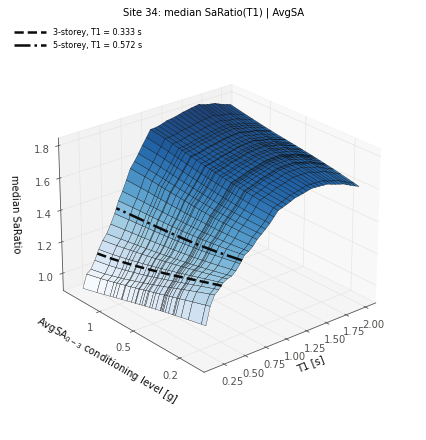

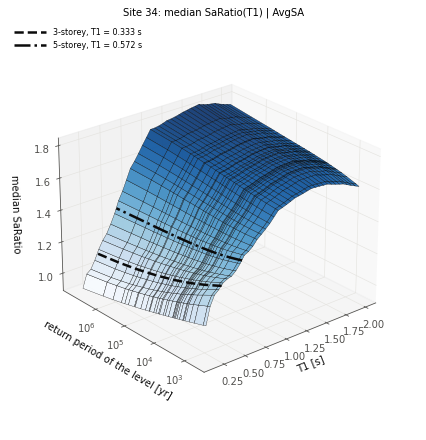

In [11]:
for x_key in X_AXES:
    surface_plot(b1, "ln_saratio_mean", "median SaRatio", np.exp, x_key,
                 f"saratio_surface_{x_key}.png", "median SaRatio(T1) | AvgSA")

saved sigma_saratio_surface_avgsa.png
saved sigma_saratio_surface_rtp.png


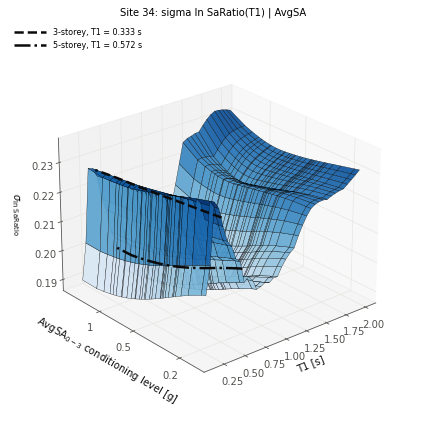

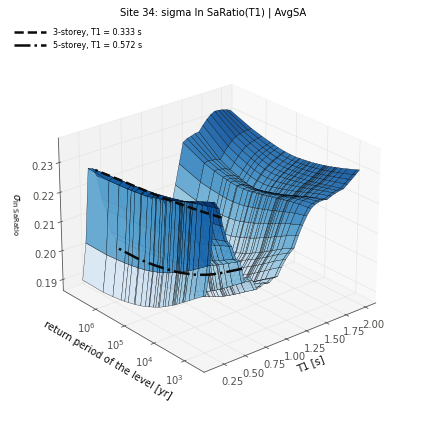

In [12]:
for x_key in X_AXES:
    surface_plot(b1, "ln_saratio_sigma", SIGMA_LABEL, lambda z: z, x_key,
                 f"sigma_saratio_surface_{x_key}.png", "sigma ln SaRatio(T1) | AvgSA")

### 6.2 SaRatio and sigma ln SaRatio vs intensity, at T1 = 0.25, 0.5, 0.75, 1.0 s

The sigma plotted is the total GCIM sigma, i.e. within- plus between-scenario spread. The split between the two is
still in the CSV (`var_within`, `var_between`) but is not plotted.

saved saratio_vs_avgsa_rtp.png
saved sigma_saratio_vs_avgsa_rtp.png


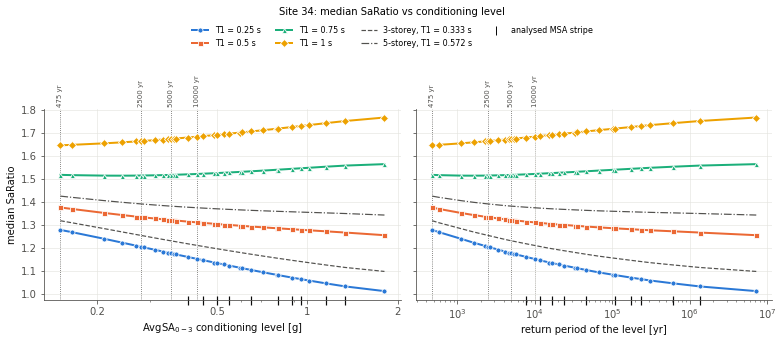

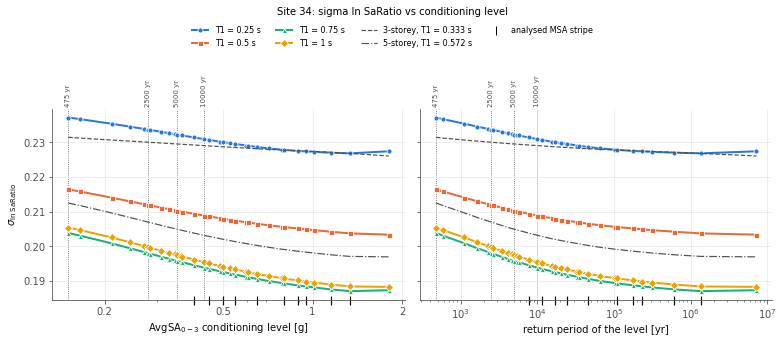

In [13]:
lines_plot(b1, "ln_saratio_mean", "median SaRatio", np.exp,
           "saratio_vs_avgsa_rtp.png", "median SaRatio vs conditioning level")
lines_plot(b1, "ln_saratio_sigma", SIGMA_LABEL, lambda z: z,
           "sigma_saratio_vs_avgsa_rtp.png", "sigma ln SaRatio vs conditioning level")

### 6.3 RSD595 and sigma ln RSD595 vs intensity

saved rsd595_vs_avgsa_rtp.png


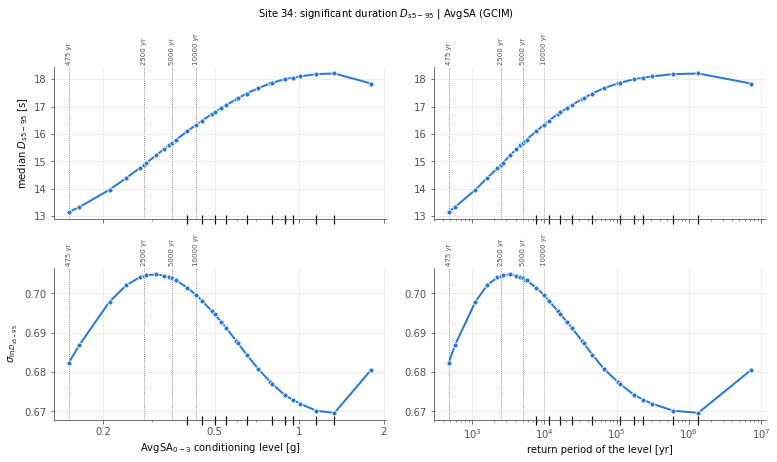

In [14]:
rsd_plot(b1)

## 7. Observations, Stage 1 (to fill in after reviewing the plots)

Questions to answer:

* **Trend with intensity.** Is median SaRatio monotonic in AvgSA / RTP at fixed T1? Is the dependence roughly linear
  in ln AvgSA or ln RTP? If so, a slope and an intercept per site might be enough.
* **Period dependence.** Is the surface separable, i.e. f(T1) + g(level)? Or does the trend with intensity change
  with period?
* **Where the spread comes from.** Where does the between-scenario variance dominate σ ln SaRatio? Does it track the
  shift in the disaggregation from one TRT to the other as intensity grows?
* **Duration.** How strongly do median RSD595 and its σ vary with level, compared with their spread across sites
  (Stage 3)?
* **Analysed stripes.** Do the analysed stripes cover the part of the curve where the covariates change fastest?

# Stage 3 — all 60 sites

## 8. Every site: compute, check, plot

The Stage 1 pipeline runs unchanged on every site: `load_site` (cached per site), `tidy_table` and `plot_site`. Each
site's seven figures and its CSV go to its own `site_NNN/` folder.

**Runtime.** On the first run, each site costs roughly 3 minutes of ground-motion-model evaluation and GCIM
computation. That is about 3 hours for all 60, plus about 10 s of plotting per site. Every site is cached as soon as
it finishes, so an interrupted run resumes where it stopped, and a second run only reloads and replots.

Progress is also appended to `12_site_covariate_trends/stage3_progress.log`, so a long run can be followed from
outside the notebook.

In [15]:
STAGE3_SITES = list(range(N_SITES))
REPLOT_SITES = True            # False: skip the per-site figures (e.g. when only the cross-site plots changed)
PROGRESS_FP = OUT_ROOT / "stage3_progress.log"

bundles, t_start = {}, time.time()
with open(PROGRESS_FP, "a") as log:
    log.write(f"\n=== stage 3 run started {time.strftime('%Y-%m-%d %H:%M:%S')} ===\n")

# Draw the 420 per-site figures with the non-interactive Agg backend. Under the
# notebook's inline backend each site's figures leaked ~80 MB even though every
# figure is closed (measured: ~7 MB/site with Agg). The inline backend is put
# back after the loop, so the cross-site figures below display as usual.
_inline_backend = plt.get_backend()
plt.switch_backend("agg")
for i, s in enumerate(STAGE3_SITES):
    t0 = time.time()
    b = load_site(s, force=FORCE_RECOMPUTE)
    tidy_table(b)
    if REPLOT_SITES:
        plot_site(b, show=False)
    # Keep only what the cross-site section needs; the bundle itself is small
    # (no disaggregations), so all 60 fit in memory comfortably.
    bundles[s] = b
    gc.collect()
    # Resident memory of this kernel, logged so a memory problem shows up in the
    # progress log before it becomes a crash.
    rss_gb = psutil.Process().memory_info().rss / 1e9
    msg = (f"site {s:2d} ({i + 1}/{len(STAGE3_SITES)}): {'computed' if b['computed'] else 'cached  '} "
           f"{time.time() - t0:6.0f} s | total {(time.time() - t_start) / 60:6.1f} min | "
           f"{len(b['levels'])} levels | RSS {rss_gb:.2f} GB")
    print(msg)
    with open(PROGRESS_FP, "a") as log:
        log.write(msg + "\n")
plt.switch_backend(_inline_backend)
with open(PROGRESS_FP, "a") as log:
    log.write(f"=== done {time.strftime('%Y-%m-%d %H:%M:%S')} ===\n")

site_covariates.pickle (C:\Users\clemettn\Documents\phd\data_processed\12_site_covariate_trends\site_000)


Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

...

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating GCIM Distributions:   0%|          | 0/1 [00:00<?, ?it/s]

site 59 (60/60): computed    237 s | total  154.3 min | 32 levels | RSS 0.41 GB


In [16]:
# ---- the combined tidy table ------------------------------------------------------
all_long = pd.concat([tidy_table(bundles[s], write=False) for s in STAGE3_SITES], ignore_index=True)
ALL_FP = OUT_ROOT / "all_sites_covariates_long.csv"
all_long.to_csv(ALL_FP, index=False)
print(f"wrote {ALL_FP.name}: {len(all_long)} rows, {all_long['site'].nunique()} sites")

# Per-site summary: how many levels, how many without a return period, sigma range.
summary = (all_long.query("T1_kind == 'grid'").groupby("site")
           .agg(n_levels=("level", "nunique"),
                n_rtp_nan=("rtp", lambda x: int(x.isna().sum() / len(T_GRID))),
                iml_min=("iml", "min"), iml_max=("iml", "max"),
                sigma_min=("ln_saratio_sigma", "min"), sigma_max=("ln_saratio_sigma", "max")))
summary.round(3).T

wrote all_sites_covariates_long.csv: 72760 rows, 60 sites


site,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,...,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59
n_levels,29.000,32.000,29.000,29.000,23.000,31.000,29.000,31.000,23.000,29.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,31.000,23.000,...,32.000,32.000,32.000,32.000,32.000,32.000,32.000,32.000,31.000,32.000,31.000,32.000,32.000,32.000,32.000,31.000,31.000,31.000,31.000,32.000
n_rtp_nan,6.000,1.000,6.000,6.000,7.000,2.000,6.000,2.000,7.000,6.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,7.000,...,1.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,2.000,1.000,2.000,1.000,1.000,0.000,1.000,2.000,2.000,2.000,2.000,1.000
iml_min,0.029,0.031,0.020,0.020,0.031,0.019,0.031,0.051,0.022,0.037,0.050,0.051,0.050,0.039,0.052,0.041,0.035,0.060,0.061,0.040,...,0.060,0.114,0.106,0.094,0.098,0.068,0.108,0.105,0.113,0.110,0.069,0.111,0.164,0.125,0.115,0.129,0.133,0.125,0.108,0.164
iml_max,1.011,1.804,1.011,1.011,0.650,1.337,1.011,1.337,0.650,1.011,1.337,1.337,1.337,1.337,1.337,1.337,1.337,1.337,1.337,0.650,...,1.804,1.804,1.804,1.804,1.804,1.804,1.804,1.804,1.337,1.804,1.337,1.804,1.804,1.804,1.804,1.337,1.337,1.337,1.337,1.804
sigma_min,0.215,0.213,0.219,0.218,0.223,0.215,0.217,0.216,0.221,0.218,0.214,0.216,0.210,0.215,0.217,0.217,0.215,0.201,0.197,0.220,...,0.214,0.206,0.185,0.213,0.214,0.215,0.214,0.213,0.210,0.213,0.212,0.215,0.145,0.214,0.215,0.145,0.145,0.145,0.145,0.144
sigma_max,0.274,0.263,0.263,0.255,0.324,0.270,0.261,0.267,0.254,0.260,0.251,0.262,0.331,0.294,0.301,0.264,0.276,0.273,0.307,0.274,...,0.250,0.242,0.241,0.258,0.256,0.250,0.246,0.249,0.260,0.273,0.261,0.252,0.270,0.277,0.276,0.270,0.270,0.270,0.270,0.270


### 8.1 Checks across all sites

1. **Structure periods vs nb 072**, for every site × structure × RTP level: 480 values of mean and σ ln SaRatio. This
   is the strongest end-to-end check. The same disaggregations and structure periods, run through an independent code
   path (nb 072's per-T1 `expected_ln_saratio` calls), must give the same numbers.
2. **Surface vs library** at three sites (first, middle, last) × three levels × three periods.
3. **Sanity.**
   * $\sigma \ge \sqrt{\text{within}}$ everywhere.
   * Every site has two structures and at least the four RTP levels.
   * Every grid T1 is present at every level.

In [17]:
# ---- 1. structure periods vs nb 072, all sites ------------------------------------
cmp_all = pd.concat([compare_vs_nb072(bundles[s]) for s in STAGE3_SITES], ignore_index=True)
worst = cmp_all[["d_mean", "d_sigma"]].max()
assert len(cmp_all) == len(STAGE3_SITES) * 2 * len(RTPS), len(cmp_all)
assert (worst < 1e-10).all(), worst
print(f"1. {len(cmp_all)} structure x RTP rows (x2 moments) == nb 072; max |diff| {worst.max():.1e}")

# ---- 2. surface vs direct library calls at three sites ----------------------------
chk_sites = sorted({STAGE3_SITES[0], STAGE3_SITES[len(STAGE3_SITES) // 2], STAGE3_SITES[-1]})
n = sum(check_vs_library(bundles[s]) for s in chk_sites)
print(f"2. surface == expected_ln_saratio at {n} (site, level, T1) triples, sites {chk_sites}")

# ---- 3. sanity -----------------------------------------------------------------------
assert (all_long["ln_saratio_sigma"] ** 2 >= all_long["var_within"] - 1e-12).all()
n_struct = all_long.query("T1_kind == 'structure'").groupby("site")["storeys"].nunique()
n_rtp = all_long.query("source == 'rtp'").groupby("site")["level"].nunique()
assert len(n_struct) == len(STAGE3_SITES) and (n_struct == 2).all()
assert len(n_rtp) == len(STAGE3_SITES) and (n_rtp == len(RTPS)).all()
grid_counts = all_long.query("T1_kind == 'grid'").groupby(["site", "level"])["T1"].nunique()
assert (grid_counts == len(T_GRID)).all()
print("3. sanity checks passed")

1. 480 structure x RTP rows (x2 moments) == nb 072; max |diff| 3.1e-15
2. surface == expected_ln_saratio at 27 (site, level, T1) triples, sites [0, 30, 59]
3. sanity checks passed


## 9. Cross-site plots

How does each covariate vary across the 60 sites, at a fixed period and intensity?

**Common intensity grids.**
* AvgSA grid: 80 log-spaced points from the lowest to the highest level of any site.
* RTP grid: 80 log-spaced points from 475 yr to the longest finite return period.

Each site's curve is interpolated onto the grid linearly in log x, **only inside that site's own range**, never
extrapolated. A low-hazard site has no values below its own 475-yr level. At a given intensity, only the sites that
actually have levels there contribute. The thin panel under each plot shows how many sites that is. Statistics are
drawn only where at least `N_MIN_SITES` contribute.

**Centre and bands.**
* **Median SaRatio and median RSD595** are lognormal-type quantities, so the statistics are taken on their logs.
  Let $m$ and $s$ be the mean and standard deviation, across sites, of $E[\ln X]$. Then:
  * the centre line is $e^{m}$, which is the across-site median under a lognormal model;
  * the bands are $e^{m \pm s}$ (±1σ) and $e^{m \pm 2s}$ (±2σ).

  They come out asymmetric on the plot, as they should.
* **σ ln SaRatio and σ ln RSD595** are already dispersions in log units. For these the centre is the plain mean across
  sites, and the bands are mean ± s and ± 2s.

The 60 grey lines are the sites' own curves at their actual levels, not the interpolated ones.

In [18]:
from matplotlib.patches import Patch

N_MIN_SITES = 10
N_GRID_PTS = 80
CROSS_DIR = OUT_ROOT / "cross_site"
CROSS_DIR.mkdir(parents=True, exist_ok=True)

# Band colours: steps of the same blue ramp as series slot 1 (light -> dark).
BAND2, BAND1, CENTRE = "#cde2fb", "#86b6ef", "#1c5cab"
SITE_LINE = dict(color=INK2, lw=0.6, alpha=0.35)

COVARIATES = {
    # column: (y label, statistics in log space?, depends on T1?, file stem)
    "ln_saratio_mean": ("median SaRatio", True, True, "cross_site_saratio"),
    "ln_saratio_sigma": (SIGMA_LABEL, False, True, "cross_site_sigma_saratio"),
    "ln_rsd595_mean": (r"median $D_{s5-95}$ [s]", True, False, "cross_site_rsd595"),
    "ln_rsd595_sigma": (r"$\sigma_{\ln D_{s5-95}}$", False, False, "cross_site_sigma_rsd595"),
}

# ---- common log-spaced intensity grids over all sites --------------------------------
lv_all = pd.concat([bundles[s]["levels"] for s in STAGE3_SITES])
X_GRID = {
    "avgsa": np.geomspace(lv_all["iml"].min(), lv_all["iml"].max(), N_GRID_PTS),
    "rtp": np.geomspace(lv_all["rtp"].min(), lv_all["rtp"].max(), N_GRID_PTS),   # NaNs are skipped
}


def site_curve(b, col, x_key, T1=None):
    # One site's curve (x, y) at its own levels, sorted by x; y is the column as stored.
    d = b["surface"][np.isclose(b["surface"]["T1"], T1)] if T1 is not None else b["rsd"]
    d = data_for(x_key, d).sort_values(X_AXES[x_key][0])
    return d[X_AXES[x_key][0]].to_numpy(), d[col].to_numpy()


def on_grid(x, y, xg):
    # Linear interpolation in log x, NaN outside the site's own range (no extrapolation).
    out = np.interp(np.log(xg), np.log(x), y)
    out[(xg < x.min()) | (xg > x.max())] = np.nan
    return out


def band_stats(col, x_key, T1=None):
    # Across-site statistics on the common grid, in the covariate's own space
    # (the stored E[ln X] for log quantities, the sigma itself otherwise).
    xg = X_GRID[x_key]
    Y = np.vstack([on_grid(*site_curve(bundles[s], col, x_key, T1), xg) for s in STAGE3_SITES])
    n = np.sum(np.isfinite(Y), axis=0)
    ok = n >= N_MIN_SITES
    m = np.where(ok, np.nanmean(np.where(ok, Y, 0.0), axis=0), np.nan)
    s = np.full(len(xg), np.nan)
    if ok.any():
        s[ok] = np.nanstd(Y[:, ok], axis=0, ddof=1)
    return xg, n, m, s


def cross_site_plot(col, T1=None):
    y_label, is_log, _, stem = COVARIATES[col]
    tf = np.exp if is_log else (lambda z: z)
    fig = plt.figure(figsize=(11, 5.6))
    gs = fig.add_gridspec(2, 2, height_ratios=[4, 1], hspace=0.08, wspace=0.08)
    rows, ax0 = [], None
    for j, x_key in enumerate(X_AXES):
        ax = fig.add_subplot(gs[0, j], sharey=ax0)
        ax0 = ax0 or ax
        axn = fig.add_subplot(gs[1, j], sharex=ax)
        xg, n, m, s = band_stats(col, x_key, T1)

        # bands first (underneath), then the 60 site lines, then the centre line on top
        ax.fill_between(xg, tf(m - 2 * s), tf(m + 2 * s), color=BAND2, lw=0, zorder=1)
        ax.fill_between(xg, tf(m - s), tf(m + s), color=BAND1, lw=0, zorder=1)
        for st in STAGE3_SITES:
            x, y = site_curve(bundles[st], col, x_key, T1)
            ax.plot(x, tf(y), zorder=2, **SITE_LINE)
        ax.plot(xg, tf(m), color=CENTRE, lw=2, zorder=3)

        # how many sites each point of the statistics rests on
        axn.plot(xg, n, color=INK2, lw=1.2, drawstyle="steps-mid")
        axn.axhline(N_MIN_SITES, color=INK2, ls=":", lw=0.8)
        axn.set_ylim(0, len(STAGE3_SITES) * 1.08)
        axn.set_ylabel("n sites", fontsize=8)
        for a in (ax, axn):
            a.set_xscale("log")
            log_ticks(a, x_key)
        ax.tick_params(labelbottom=False)
        axn.set_xlabel(X_AXES[x_key][1])
        if j == 0:
            ax.set_ylabel(y_label)
        else:
            ax.tick_params(labelleft=False)

        # T1 = NaN (float) for the duration covariates, which do not depend on T1;
        # a None here would make an all-NA object column that pandas warns about.
        rows.append(pd.DataFrame({"covariate": col, "T1": np.nan if T1 is None else float(T1),
                                  "x_axis": x_key, "x": xg, "n_sites": n,
                                  "centre": tf(m), "stat_mean": m, "stat_sd": s,
                                  "lo_2sd": tf(m - 2 * s), "lo_1sd": tf(m - s),
                                  "hi_1sd": tf(m + s), "hi_2sd": tf(m + 2 * s)}))

    centre_lab = "median across sites, $e^{m}$" if is_log else "mean across sites"
    handles = [Line2D([], [], lw=2, color=CENTRE, label=centre_lab),
               Patch(color=BAND1, label="±1σ across sites"),
               Patch(color=BAND2, label="±2σ across sites"),
               Line2D([], [], label=f"individual site ({len(STAGE3_SITES)})", **SITE_LINE)]
    fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0), fontsize=8)
    what = f"{y_label} at T1 = {T1:g} s" if T1 is not None else y_label
    fig.suptitle(f"All {len(STAGE3_SITES)} sites: {what}", y=1.05, fontsize=10)
    fname = f"{stem}_T{T1:g}.png" if T1 is not None else f"{stem}.png"
    save_fig(fig, CROSS_DIR, fname)
    return pd.concat(rows, ignore_index=True)

saved cross_site_saratio_T0.25.png
saved cross_site_saratio_T0.5.png
saved cross_site_saratio_T0.75.png
saved cross_site_saratio_T1.png


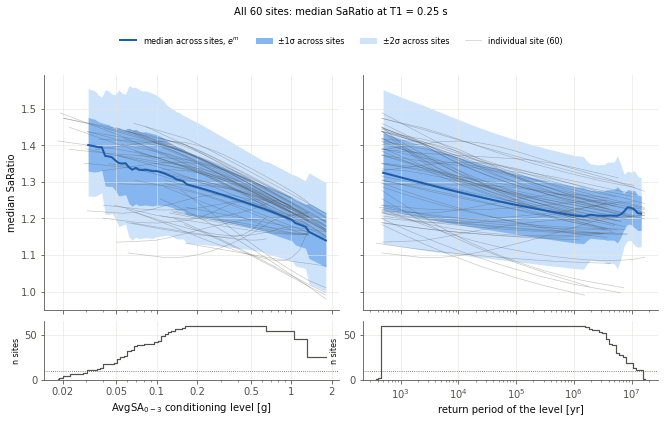

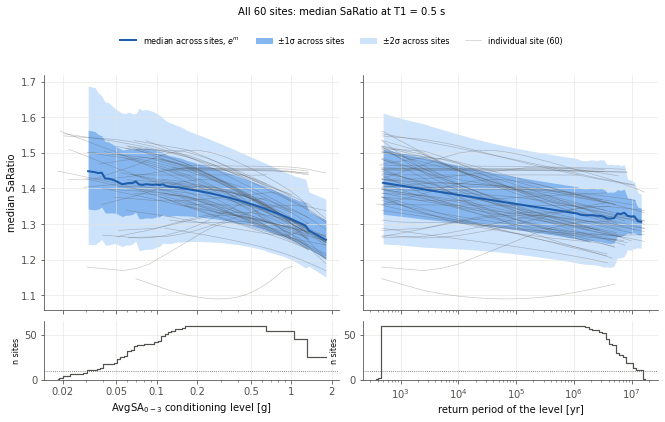

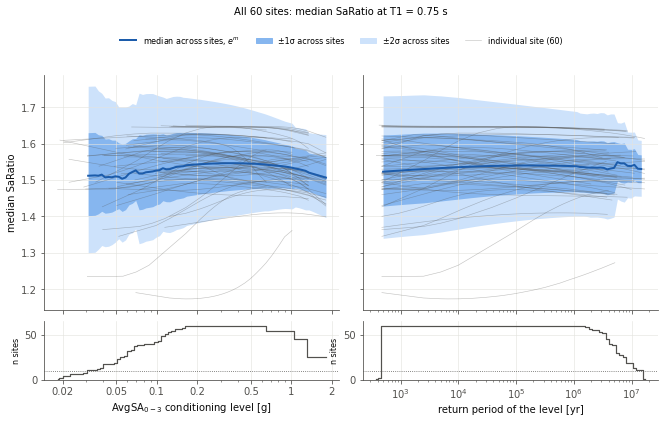

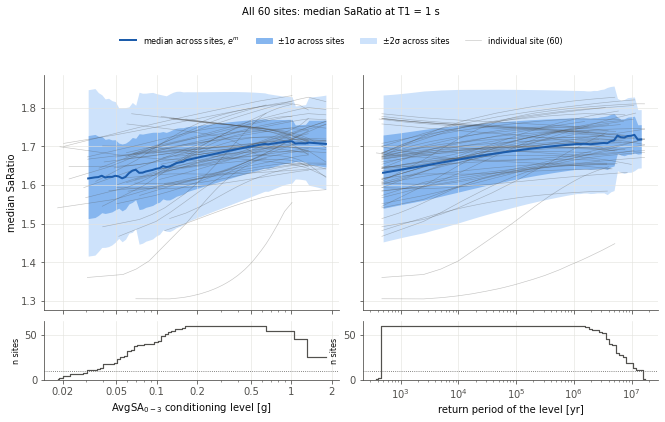

In [19]:
band_tables = []
for T1 in LINE_T1S:
    band_tables.append(cross_site_plot("ln_saratio_mean", T1))

saved cross_site_sigma_saratio_T0.25.png
saved cross_site_sigma_saratio_T0.5.png
saved cross_site_sigma_saratio_T0.75.png
saved cross_site_sigma_saratio_T1.png


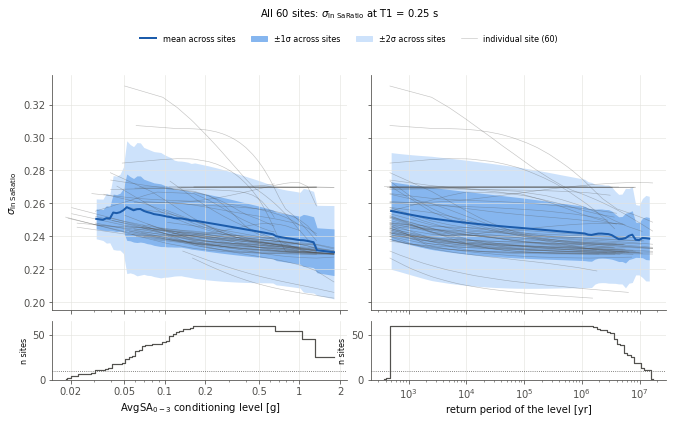

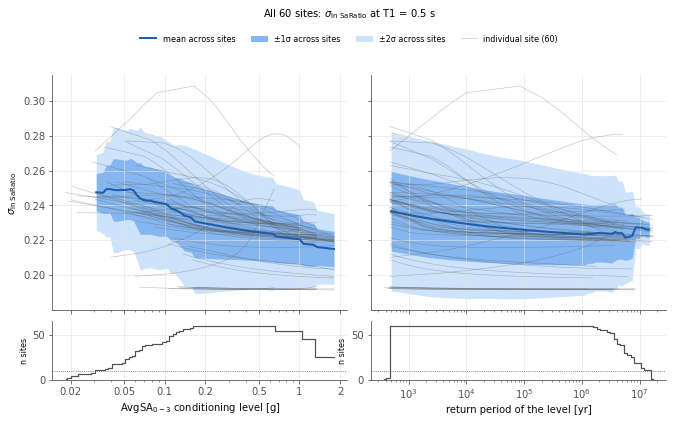

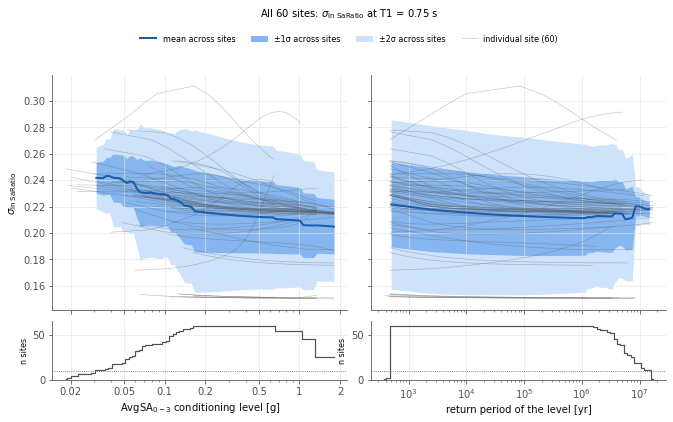

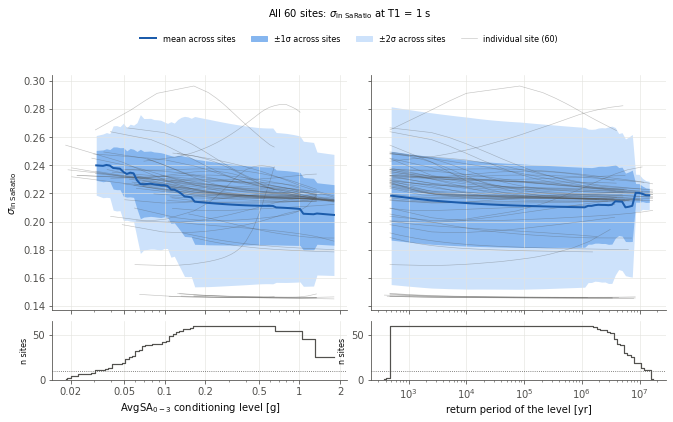

In [20]:
for T1 in LINE_T1S:
    band_tables.append(cross_site_plot("ln_saratio_sigma", T1))

saved cross_site_rsd595.png
saved cross_site_sigma_rsd595.png
wrote cross_site_band_stats.csv


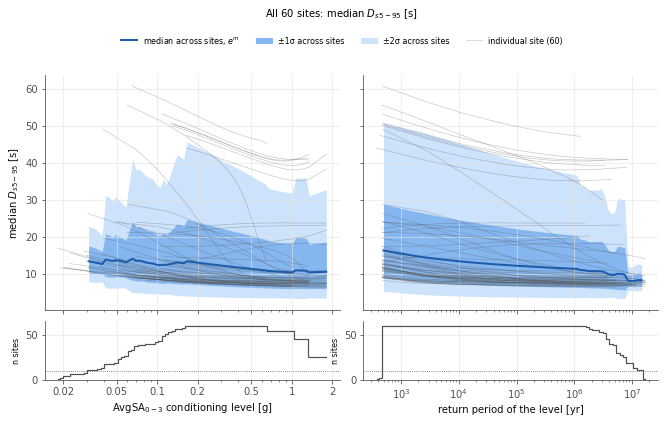

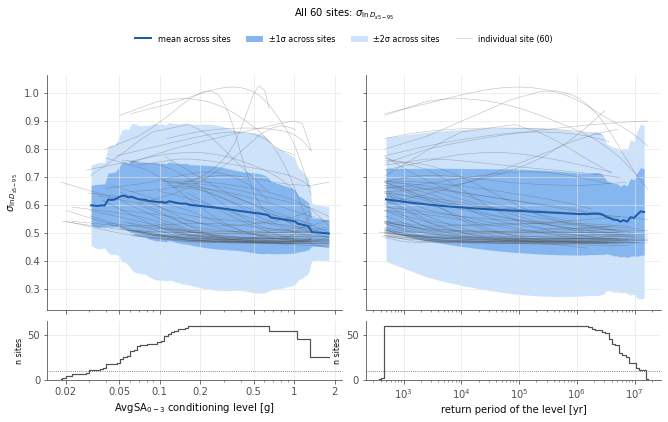

In [21]:
band_tables.append(cross_site_plot("ln_rsd595_mean"))
band_tables.append(cross_site_plot("ln_rsd595_sigma"))

BAND_FP = CROSS_DIR / "cross_site_band_stats.csv"
# The duration tables have T1 all-NaN by design (no period dependence); pandas
# warns that it may change dtype handling for such columns in future. The
# column is float either way, so the warning is silenced here only.
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    bands = pd.concat(band_tables, ignore_index=True)
bands.to_csv(BAND_FP, index=False)
print(f"wrote {BAND_FP.name}")

## 10. Observations, Stage 3 (to fill in after reviewing the plots)

* **Spread across sites vs change with intensity.** At a fixed intensity, is the across-site band wider or narrower
  than the change of the median along the intensity axis? A narrow band suggests that intensity (or return period)
  alone predicts the covariate. A wide band means a site descriptor is needed.
* **AvgSA vs RTP.** Are the site lines more tightly bunched against AvgSA or against return period? That says which
  axis a simplified model should be built on.
* **Outlying sites.** Which sites sit outside ±2σ? Do they share a tectonic setting, for example subduction or
  Vrancea, which the disaggregation would identify?
* **Duration.** Is σ ln RSD595 essentially constant across sites and levels? If so, it could be treated as a constant.

## 11. Fisher vs uniform stripe weighting of the record and target covariates, per site

Nb 072 (s. 8.10) collapses each row's per-stripe covariates into one number per row by a weighted sum over the
row's MSA stripes, $\sum_k w_{ik}\,(\cdot)_{ik}$. It does this with two weightings:

* **uniform**, $w_{ik} = 1/n_i$: every stripe counts equally;
* **Fisher**, $w_{ik}$ from the Fisher information of the stripe about the IDA-FX fragility median: stripes near the
  median, which pin the fragility down, count more.

This figure shows how much the choice of weighting moves the two families of covariates that nb 073 regresses on:

| column (left) | `drec_ln_{q}_{s}_{w}` | records **minus** GCIM: how far the selected record set misses its own target |
|---|---|---|
| column (right) | `d_ln_{q}_{s}_{w}` | GCIM **minus** FEMA P695: how far the site's target sits from the fixed set |

with one row of panels per covariate: mean and σ of ln SaRatio, then mean and σ of ln D$_{s5-95}$. All values are in
ln units. Since `drec_` + `d_` = records − FEMA for either weighting (nb 072 s. 8.10), the two columns together also
show where the total record-set difference comes from.

**Reading the plot.** Each site carries two rows (3- and 5-storey), so each site gets four points per panel:

* colour and marker give the **weighting** (the same in every panel): uniform is blue circles, Fisher is aqua
  triangles;
* fill gives the **structure**: filled is the 3-storey, hollow the 5-storey. The two are nudged ±0.15 apart on the
  site axis so they do not sit on top of each other.

Where a blue circle and an aqua triangle overlap, the weighting does not matter for that row. A visible gap means the
covariate changes along the stripes, and the two weightings read different parts of that change.

Data: `data_processed/10_fragility_curve_statistical_analysis/fragility_regression_dataset_AvgSA_03.csv` (nb 072).


saved C:\Users\clemettn\Documents\phd\data_processed\12_site_covariate_trends\cross_site\fisher_vs_uniform_covariates_by_site_AvgSA_03.png


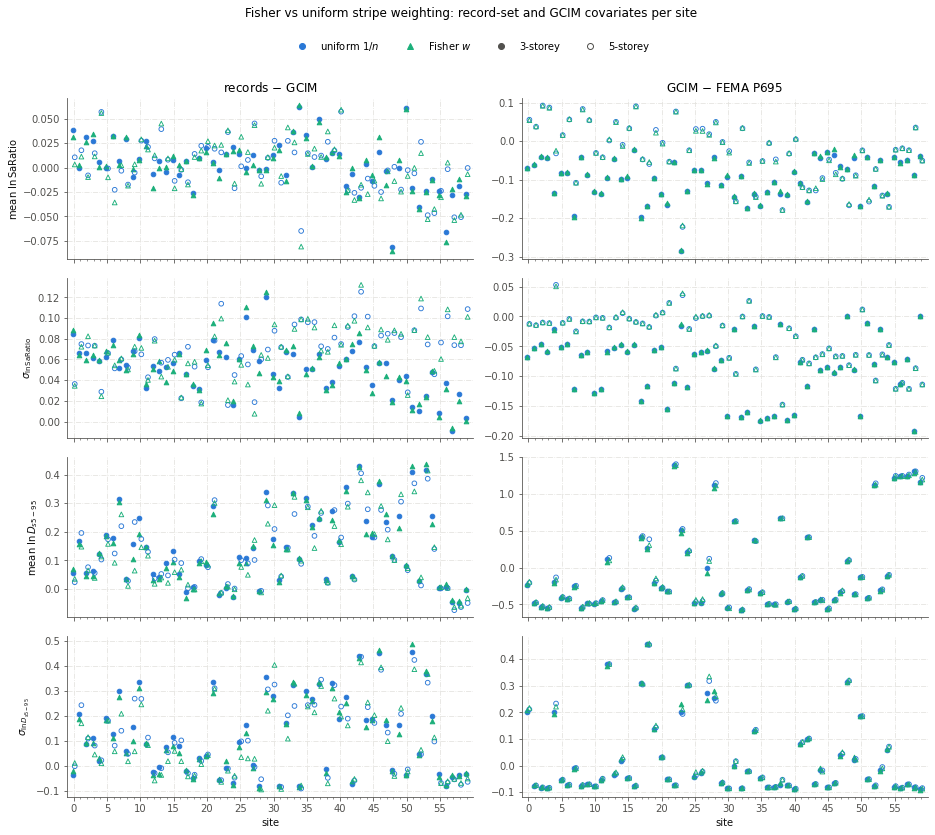

In [22]:
# -----------------------------------------------------------------------------
# Fisher vs uniform weighted covariates, per site (4 x 2 small multiples)
# -----------------------------------------------------------------------------
# The regression dataset of nb 072: 120 rows, one per (site, structure). It sits
# one folder above REG_PTH (10_fragility_curve_statistical_analysis/).
REG_DATASET_FP = REG_PTH.parent / f"fragility_regression_dataset_{IM_TAG}.csv"
reg = pd.read_csv(REG_DATASET_FP)
assert len(reg) == 2 * N_SITES, len(reg)                      # full study: 60 sites x 2 structures
assert reg.groupby("site")["n_storeys"].nunique().eq(2).all()  # every site has a 3s and a 5s row

WEIGHT_DIR = OUT_ROOT / "cross_site"
WEIGHT_DIR.mkdir(parents=True, exist_ok=True)

# Panel grid. Rows: the four covariates, as (column stem, y-label). Columns: the
# two contrast families, as (column prefix, panel title). The full column name
# is f"{prefix}{stem}_{weighting}", e.g. "drec_ln_saratio_mean_fisher".
COV_ROWS = [
    ("ln_saratio_mean",  r"mean $\ln \mathrm{SaRatio}$"),
    ("ln_saratio_sigma", r"$\sigma_{\ln \mathrm{SaRatio}}$"),
    ("ln_ds595_mean",    r"mean $\ln D_{s5-95}$"),
    ("ln_ds595_sigma",   r"$\sigma_{\ln D_{s5-95}}$"),
]
CONTRAST_COLS = [
    ("drec_", "records $-$ GCIM"),
    ("d_",    "GCIM $-$ FEMA P695"),
]

# The two weightings: (column suffix, legend label, colour, marker). These are
# the same colour/marker pairs nb 072 uses for the weights themselves (uniform:
# slot 1 blue circles, Fisher: slot 3 aqua triangles), so the series read the
# same across notebooks, and the marker shape keeps them apart without colour.
WEIGHTINGS = [
    ("unif",   "uniform $1/n$", "#2a78d6", "o"),
    ("fisher", "Fisher $w$",    "#1baf7a", "^"),
]

# The two structures at a site share the site's x position. They are told apart
# by marker fill (filled = 3-storey, hollow = 5-storey) and nudged sideways by a
# small offset so the points of one site do not overplot each other.
STOREY_STYLE = {3: dict(dx=-0.15, filled=True), 5: dict(dx=+0.15, filled=False)}

fig, axes = plt.subplots(len(COV_ROWS), len(CONTRAST_COLS), figsize=(13, 11),
                         sharex=True, squeeze=False)

for r, (stem, ylabel) in enumerate(COV_ROWS):
    for c, (prefix, title) in enumerate(CONTRAST_COLS):
        ax = axes[r, c]
        for n_st, st in STOREY_STYLE.items():
            rows = reg[reg["n_storeys"] == n_st]
            x = rows["site"].to_numpy() + st["dx"]
            for suffix, _, colour, marker in WEIGHTINGS:
                ax.scatter(
                    x, rows[f"{prefix}{stem}_{suffix}"],
                    marker=marker, s=22, linewidths=0.9,
                    edgecolors=colour,
                    # hollow markers for the 5-storey rows: face is transparent
                    facecolors=colour if st["filled"] else "none",
                    zorder=3,
                )
        # Grid as requested: linewidth 0.8, dash-dot, drawn below the points.
        ax.grid(True, lw=0.8, ls="-.")
        ax.set_axisbelow(True)
        if r == 0:
            ax.set_title(title)
        if c == 0:
            ax.set_ylabel(ylabel)
        if r == len(COV_ROWS) - 1:
            ax.set_xlabel("site")

# Site integers on the shared x axis: a tick every 5 sites, minor tick on each.
axes[-1, 0].set_xlim(-1, N_SITES)
for ax in axes[-1]:
    ax.set_xticks(range(0, N_SITES, 5))
    ax.set_xticks(range(N_SITES), minor=True)

# One legend for the whole figure: the two weightings (colour + marker) and the
# two structures (filled / hollow), drawn as marker-only handles (no lines).
handles = [Line2D([], [], ls="none", marker=m, color=col, markerfacecolor=col, label=lab)
           for _, lab, col, m in WEIGHTINGS]
handles += [Line2D([], [], ls="none", marker="o", color=INK2,
                   markerfacecolor=INK2 if st["filled"] else "none", label=f"{n}-storey")
            for n, st in STOREY_STYLE.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Fisher vs uniform stripe weighting: record-set and GCIM covariates per site", y=1.05)
fig.tight_layout()

# facecolor="w": opaque white PNG background in any viewer (CLAUDE.md s.4).
fig_fp = WEIGHT_DIR / f"fisher_vs_uniform_covariates_by_site_{IM_TAG}.png"
fig.savefig(fig_fp, dpi=200, bbox_inches="tight", facecolor="w")
print(f"saved {fig_fp}")
plt.show()
